> **Superseded by `06_model_comparison.ipynb`.** This notebook ran the first four-way comparison on `labelled_dataset_v3.csv` (2,023 posts, 405 test posts; LogReg accuracy 0.63). The **final results** use the final file `data/grab_sentiment_clean.csv` (**2,015 posts**, train 1,612 / test 403): Logistic Regression accuracy **0.618**, macro-F1 **0.509** (see `result/` and notebook 06). Report those numbers, not the ones below.
>
> The Manglish tools explained in Section 1 are the same ones notebook 06 uses. The notebook still runs top to bottom for reference, with saving switched off (`SAVE_OUTPUTS = False`) so the v3 file and the old figures are not overwritten.

# 04 · Sentiment analysis (VADER vs. Manglish-aware VADER vs. TF-IDF + Logistic Regression)

**What this notebook does, in plain English**

1. Builds the final labelled dataset **`labelled_dataset_v3.csv`** (2,000+ posts in English, Malay and Manglish).
2. Scores every post four ways:
   * **(a) VADER**: a standard English sentiment dictionary. It knows "terrible" but not "teruk".
   * **(b) VADER + Manglish lexicon**: we added ~50 Malay/Manglish words with scores (`src/manglish_lexicon.py`).
   * **(c) VADER + lexicon + normalisation**: we also rewrite short forms first, e.g. *"tak best"* → *"not best"*
     (`src/manglish_normalise.py`).
   * **(d) TF-IDF + Logistic Regression**: a machine-learning model that *learns* from our labelled posts.
3. Compares them against our labels on the same held-out 20% of posts (accuracy, macro-F1, confusion matrices).

> The "correct answers" are the labels in the `sentiment` column (Claude read every post against
> `data/LABELLING_GUIDE.md`; a teammate corrected some). The optional hand-check step
> (`data/labelling/hand_check.csv`, Section 5) is no longer needed and is switched off.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))
import pandas as pd
from src.merge_v3 import build_v3
from src.evaluate import score_all, compare, fixed_by_manglish, hand_check_sample, METHODS
from src.label import label_distribution
from src.manglish_lexicon import MANGLISH_LEXICON, BOOSTERS
from src.manglish_normalise import WORD_MAP, PHRASES, PARTICLES
pd.set_option("display.max_colwidth", 120)
ROOT = pathlib.Path.cwd().parent

In [2]:
SAVE_OUTPUTS = False   # True would overwrite labelled_dataset_v3.csv, posts_scored.csv and the old comparison outputs

## 1. The Manglish tools
The lexicon gives each Malay/Manglish word a score from −4 (very negative) to +4 (very positive), the same scale VADER uses.
The normaliser rewrites short forms so VADER's own rules (like "not" flipping the next word) work on Manglish.

In [3]:
print(len(MANGLISH_LEXICON), "lexicon words;", len(BOOSTERS), "intensifiers:", BOOSTERS)
pd.Series(MANGLISH_LEXICON).sort_values().to_frame("score").T

49 lexicon words; 2 intensifiers: {'memang': 0.293, 'mmg': 0.293}


,scam,penipu,kurang_ajar,tipu,teruk,sakit_hati,hampeh,menyampah,sial,bodoh,...,cun,sedap,sopan,cepat,padu,puas_hati,mantap,terbaik,memang_best,bagus
score,-3.0,-3.0,-3.0,-3.0,-2.5,-2.5,-2.5,-2.5,-2.5,-2.5,...,2.0,2.0,2.0,2.0,2.0,2.3,2.5,2.5,2.5,2.5


In [4]:
print("Short forms:", WORD_MAP)
print("Joined phrases:", PHRASES)
print("Particles removed for scoring:", sorted(PARTICLES))

Short forms: {'x': 'not', 'tak': 'not', 'tk': 'not', 'xde': 'not', 'takde': 'not', 'tiada': 'not', 'tidak': 'not', 'bukan': 'not', 'xboleh': 'cannot', 'takboleh': 'cannot', 'tak_boleh': 'cannot', 'xnak': 'dont want', 'taknak': 'dont want', 'tak_nak': 'dont want', 'jgn': 'dont', 'jangan': 'dont', 'sgt': 'very', 'sangat': 'very', 'byk': 'many', 'banyak': 'many', 'dh': 'already', 'dah': 'already', 'da': 'already', 'sudah': 'already', 'ni': 'this', 'tu': 'that', 'boleh': 'can', 'blh': 'can'}
Joined phrases: {'tak boleh': 'tak_boleh', 'tak nak': 'tak_nak', 'puas hati': 'puas_hati', 'tak puas hati': 'tak puas_hati', 'memang best': 'memang_best', 'kurang ajar': 'kurang_ajar', 'makan gaji': 'makan_gaji', 'buang masa': 'buang_masa', 'terima kasih': 'terima_kasih', 'sakit hati': 'sakit_hati'}
Particles removed for scoring: ['ah', 'hor', 'kan', 'la', 'lah', 'leh', 'liao', 'lor', 'mah', 'meh', 'sia', 'weh', 'wei']


## 2. Build the final dataset (v3)
v2 (1,341 English posts) + posts that were previously dropped only for being Malay (re-cleaned with the new language rule)
+ new X/Twitter posts collected with Malaysian Malay search words. `labelled_dataset_v2.csv` is backed up, never changed.

In [5]:
v3, irrelevant = build_v3()
if SAVE_OUTPUTS:   # off: keep the saved files from the original run
    v3.to_csv(ROOT / "data/processed/labelled_dataset_v3.csv", index=False)
print(f"{len(v3):,} posts, {len(v3.columns)} columns")
print("By platform:", v3.platform.value_counts().to_dict())
print("By language group:", v3.lang_group.value_counts().to_dict())
print("Flagged unsure:", int(v3.unsure.fillna(False).astype(bool).sum()))
label_distribution(v3.sentiment)

2,023 posts, 29 columns
By platform: {'twitter': 1036, 'reddit': 681, 'threads': 224, 'tiktok': 51, 'facebook': 31}
By language group: {'en': 1353, 'ms': 530, 'mixed': 140}
Flagged unsure: 472


,count,percent
sentiment,,
positive,215,10.6
negative,901,44.5
neutral,907,44.8


In [6]:
pd.crosstab(v3.lang_group, v3.sentiment, margins=True)

sentiment,negative,neutral,positive,All
lang_group,,,,
en,544,637,172,1353
mixed,77,48,15,140
ms,280,222,28,530
All,901,907,215,2023


## 3. Score every post four ways

In [7]:
scored = score_all(v3)
if SAVE_OUTPUTS:   # off: keep the saved files from the original run
    scored.to_csv(ROOT / "data/processed/posts_scored.csv", index=False)
scored[["text_clean", "sentiment", "a_vader_plain", "c_vader_lexicon_norm", "d_tfidf_logreg"]].sample(8, random_state=1)

,text_clean,sentiment,a_vader_plain,c_vader_lexicon_norm,d_tfidf_logreg
1422,@grabmy if your driver didn't like auto accept please remove from your system laa... Accept job tapi complaint buat ...,negative,negative,negative,negative
1555,"@user @user @GrabMY dalam islam boleh ke amek bukan hak? klo x ambik skalipun, responsibility mane?",neutral,positive,negative,neutral
1210,KOTA KINABALU: A 29-year-old Grab motorcycle rider was charged in the Magistrate's Court on Tuesday with trafficking...,neutral,negative,negative,neutral
1219,@grabmy there's an issue with my payment via GrabPay to Firefly. The payments were deducted from my card but it didn...,negative,positive,positive,negative
370,"We're not subsidizing the company, but the driver. If the driver's cost is increased, they would demand higher fare,...",neutral,positive,positive,negative
1141,"@user @user i left with 30 minutes left in fp2 went to d-village, took a grab to salak tingi, switched to putrajaya ...",neutral,positive,positive,neutral
1701,@grabmy pun dah kena cyberattack ke? [face with tears of joy],negative,negative,negative,negative
713,URL Grab's policy does not state that driver-partners are responsible for preparing change A quick check on Grab's t...,neutral,positive,positive,neutral


## 4. Comparison (main finding)
All four methods are judged on the **same 405 test posts** (v3 data; the final run in notebook 06 uses 403) that the machine-learning model never saw while learning.
*Macro-F1* averages the F1 score of the three classes equally, so the small positive class counts as much as the others.

In [8]:
results, cms, test = compare(scored, fig_dir=ROOT / "outputs/figures" if SAVE_OUTPUTS else None)
if SAVE_OUTPUTS:   # off: keep the old comparison table
    results.to_csv(ROOT / "outputs/tables/results_comparison.csv", index=False)
results

,method,accuracy,macro_f1,f1_negative,f1_neutral,f1_positive,n_test
0,(a) VADER,0.37,0.360,0.452,0.353,0.276,405
1,(b) VADER + Manglish lexicon,0.42,0.397,0.562,0.338,0.290,405
2,(c) VADER + lexicon + normalisation,0.42,0.395,0.563,0.338,0.284,405
3,(d) TF-IDF + Logistic Regression,0.63,0.549,0.667,0.653,0.329,405


In [9]:
from sklearn.metrics import accuracy_score, f1_score
non_en = test[test.lang_group != "en"]
pd.DataFrame([{"method": name, "accuracy": round(accuracy_score(non_en.sentiment, non_en[c]), 3),
               "macro_f1": round(f1_score(non_en.sentiment, non_en[c], average="macro"), 3)}
              for c, name in METHODS.items()]).assign(n_test=len(non_en))

,method,accuracy,macro_f1,n_test
0,(a) VADER,0.368,0.298,136
1,(b) VADER + Manglish lexicon,0.515,0.429,136
2,(c) VADER + lexicon + normalisation,0.515,0.412,136
3,(d) TF-IDF + Logistic Regression,0.640,0.509,136


The table above repeats the comparison on **Malay and mixed posts only**, where the Manglish lexicon should matter most.
Confusion matrices are saved as `outputs/figures/confusion_<method>.png`.

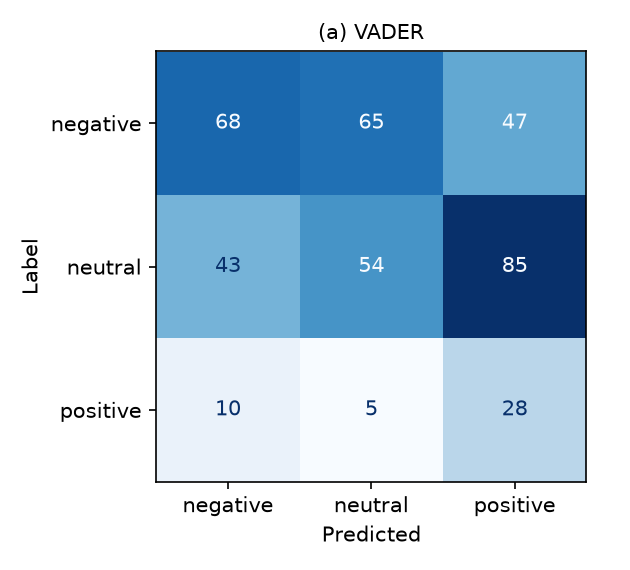

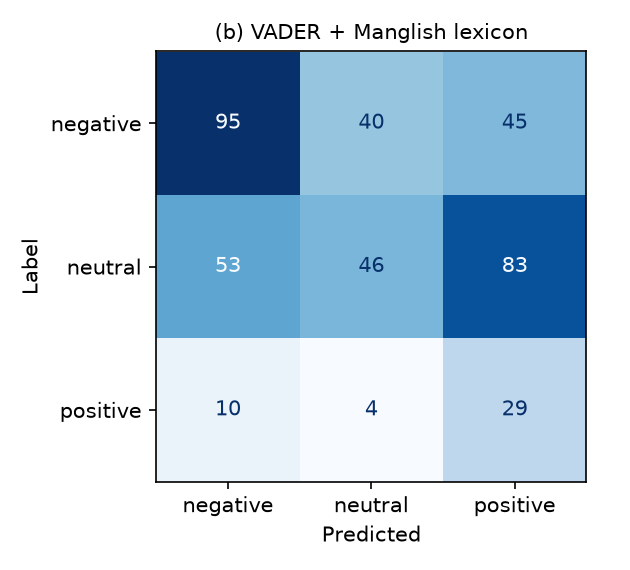

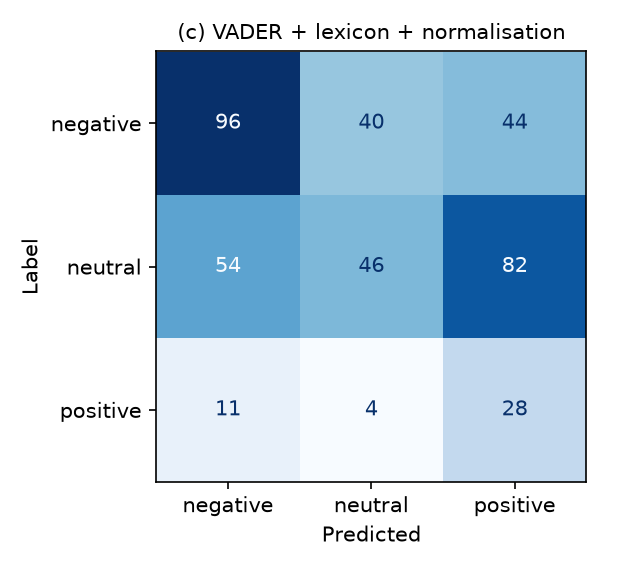

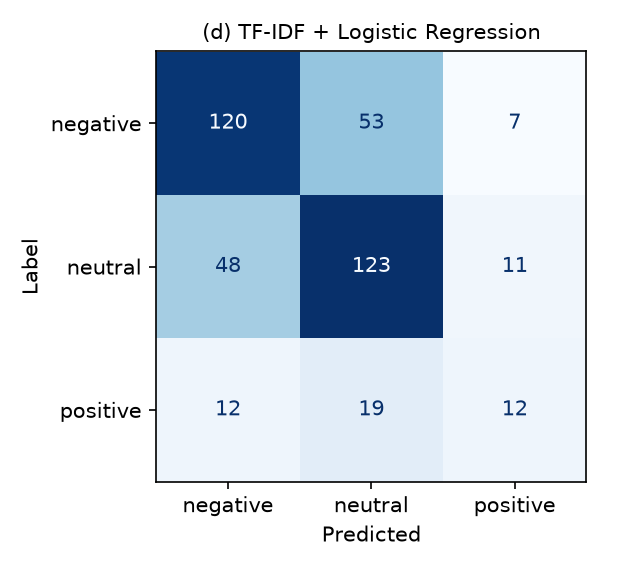

In [10]:
# The old confusion-matrix PNGs from this notebook; the final ones are in result/figures/ (notebook 06)
from IPython.display import Image, display
for c in METHODS:
    display(Image(filename=str(ROOT / f"outputs/figures/confusion_{c}.png"), width=330))

### Examples where plain VADER was wrong and Manglish-aware VADER was right

In [11]:
fixed_by_manglish(test, n=10)

,post_id,platform,lang_group,sentiment,a_vader_plain,vader_plain_compound,c_vader_lexicon_norm,vader_lexnorm_compound,text_clean
688,osv6bv7,reddit,en,negative,neutral,-0.0387,negative,-0.3291,So the grab driver told me apparently there's an army of grab drivers waiting near the airport to take on airport ri...
512,o2m4ivz,reddit,en,neutral,positive,0.1280,neutral,0.0000,I think there's a settings where if some food/drinks are not available you can basically pick to whenever you can re...
1487,2040692032151396801,twitter,mixed,negative,positive,0.3182,negative,-0.2960,"@GrabMY @user Barua lah, ni benda common sial dekat malaysia. Please fuckin fix your driver and monitor their chat"
1623,2107778662481428700,twitter,mixed,positive,neutral,0.0000,positive,0.5423,Bagus bebeno Function Saver by @GrabMY ni.. URL
1981,2118333092171796820,twitter,mixed,negative,positive,0.1901,negative,-0.4437,I wanna go Midtown tomorrow but cant go due to rain and Friday nak balik rumah pun jam sangat lah. Situ no public tr...
1387,1993182173273448564,twitter,mixed,negative,neutral,0.0000,negative,-0.3612,Its gonna rain soon. Asked my mom to fetch me cozz grab mahal nak mampuih URL
1372,1991727131727155602,twitter,mixed,negative,positive,0.4588,negative,-0.1280,@user Screeching halt when I realized the vendor is Richiamo yg org kutuk xsedap and the delivery app uplift giler b...
1384,1992800957483380867,twitter,ms,negative,positive,0.1531,negative,-0.1779,"Kita ni pun bukannya buta peghot dari ataih kapaiterbang dah order grab. Kita ni dah sampai arrival hall dah, siap t..."
1764,fb_2136315163989430,facebook,ms,negative,neutral,0.0000,negative,-0.3612,Grab mahal
1390,1994275148124275174,twitter,ms,negative,neutral,0.0000,negative,-0.3612,"Nak balik, tapi grab mahal hm"


## 5. (Optional, not needed) Hand-check sample
This step is **no longer needed** for the final results: notebook 06 evaluates every method on the final labelled file. It is kept only for reference and is switched off (`RUN_HAND_CHECK = False`).

200 posts, stratified by label and platform. Type your own label in **`my_label`** (positive / negative / neutral)
and save as `data/labelling/hand_check.csv`. Then re-run `compare(...)` with `truth_col="my_label"` on those rows.

In [12]:
RUN_HAND_CHECK = False   # optional step, not needed for the final results
if RUN_HAND_CHECK:
    hc_path = ROOT / "data/labelling/hand_check.csv"
    if not hc_path.exists():
        hand_check_sample(v3).to_csv(hc_path, index=False)
    hc = pd.read_csv(hc_path)
    print(len(hc), "rows; filled in so far:", int(hc.my_label.notna().sum()))
    hc.claude_label.value_counts()
else:
    print("Optional hand-check step skipped (RUN_HAND_CHECK = False).")

Optional hand-check step skipped (RUN_HAND_CHECK = False).
